# Лабораторна робота № 1

## Вхідний аналіз набору даних

**Дисципліна:** Інтелектуальний аналіз та візуалізація даних (СК26)
**Тривалість:** 2 год аудиторно + 3 год самостійної роботи · **Максимальна оцінка:** 4 бали

---

### Мета роботи

Пригадати роботу в Jupyter Notebook, бібліотеці `pandas` та побудову графіків —
і зробити це не на навчальному прикладі, а на реальному файлі, який ніхто не готував
спеціально для вас.

Ця робота виконується **до першої лекції**. Нічого нового знати не потрібно: усе,
що знадобиться, ви вже проходили в попередніх курсах. Усі поняття, яких ви тут
торкнетеся мимохідь, отримають назви й пояснення на лекціях 3 і 4.

### Дані

Файл `20171129_FINAL_FINAL.xlsx`, аркуш `Sheet1` — спостереження космічної погоди
за 28 серпня — 22 вересня 2017 року, зібрані з трьох різних джерел.

Файл видається **як є**, рівно в тому вигляді, у якому його колись вивантажили.
Ніхто не приводив його до ладу, і саме в цьому сенс: справжні дані здебільшого
надходять саме такими.

### Що ви маєте зробити

| Етап | Зміст | Де |
|---|---|---|
| 1 | Розібратися, що взагалі лежить у файлі | аудиторно |
| 2 | Виділити три таблиці й привести їх до робочого вигляду | аудиторно |
| 3 | Скласти паспорт даних: що є, чого бракує, що виглядає дивно | аудиторно |
| 4 | Об'єднати три таблиці в одну | аудиторно |
| 5 | Побудувати п'ять графіків, кожен — відповідь на питання | аудиторно + самостійно |
| 6 | Порівняти два графіки одних і тих самих даних | самостійно |
| 7 | Записати три спостереження про дані | самостійно |
| 8 | Декларація про використання інструментів ШІ | самостійно |

### Що здається

1. Цей файл `.ipynb` із заповненими розв'язками. **Ноутбук має виконуватися згори
   донизу на чистому ядрі** (Kernel → Restart & Run All) без помилок — це перевіряється
   першою дією на захисті.
2. Файл `master_hourly.csv` — об'єднана таблиця з етапу 4.
3. Експорт ноутбука у HTML або PDF.
4. Заповнена декларація (етап 8). Без неї фінальна самоперевірка не проходить.

### Критерії оцінювання

| Бали | Що досягнуто |
|---|---|
| 0 | Дані не опрацьовано, графіки не побудовано або побудовано з грубими помилками |
| 1 | Таблиці прочитано й кілька графіків побудовано, але типи графіків не відповідають даним, дивних значень не помічено |
| 2 | Таблиці розібрано й об'єднано, графіки коректні та підписані, але висновків під ними немає або вони формальні |
| 4 | Усе вище виконано, знайдено й пояснено дивні значення, під кожним графіком є змістовний висновок про дані |

**Головне про оцінку:** бали ставляться не за наявність графіка, а за речення під ним.
Код, який нічого не пояснює, коштує двох балів з чотирьох.

---
## Нагадування про Jupyter

Якщо давно не працювали — три речі, які знадобляться сьогодні:

* `Shift+Enter` виконує клітинку, `Esc` `A` / `Esc` `B` додає клітинку вище / нижче,
  `Esc` `M` перетворює клітинку на текстову (Markdown), `Esc` `Y` — назад на код.
* **Порядок виконання має значення.** Якщо ви правили клітинки в довільному порядку,
  результат може залежати від історії запусків. Перед здачею обов'язково
  **Kernel → Restart & Run All** — так ви побачите ноутбук очима викладача.
* Текстові клітинки — не прикраса. Висновки пишуться в них, а не в коментарях до коду.

---
## Крок 0. Ваші дані та варіант

Заповніть три змінні й виконайте обидві клітинки. Друга надрукує **ваше
індивідуальне завдання** — воно відрізняється від завдання сусіда.

In [40]:
ПІБ = 'Савков Олександр'
ГРУПА = 'ші-33'
ВАРІАНТ = 6

assert ПІБ and ГРУПА and ВАРІАНТ, 'Заповніть ПІБ, ГРУПУ та ВАРІАНТ'

In [41]:
# --- клітинку не редагувати: вона видає ваше персональне завдання ------------
ПОТОКИ = ['P>1', 'P>5', 'P>10', 'P>30', 'P>50', 'P>100', 'E>0.8', 'E>2.0']

ПАРИ = [('швидкість вітру', 'густина вітру'),
        ('швидкість вітру', 'потік P>10'),
        ('густина вітру', 'потік P>1'),
        ('радіопотік F10.7', 'потік P>10'),
        ('радіопотік F10.7', 'швидкість вітру'),
        ('потік E>0.8', 'потік P>10')]

АГРЕГАТИ = ['середнє', 'максимум', 'медіана', 'мінімум']

ПИТАННЯ = [
    'Скільки годин за все вікно ваш потік перевищував своє власне медіанне значення?',
    'У яку добу середнє значення вашого потоку було найбільшим? А найменшим?',
    'О котрій годині доби потік E>0.8 у середньому найбільший? Побудуйте графік середнього за годинами доби.',
    'Яка частка рядків об’єднаної таблиці має пропуск хоча б в одному стовпці?',
    'У який день радіопотік F10.7 був найбільшим і чи збігається цей день з піком вашого потоку?',
    'Порівняйте медіану вашого потоку за перший і за другий тиждень спостережень. У скільки разів вони відрізняються?',
    'Скільки годин поспіль тривала найдовша неперервна серія «активних» годин (група з етапу 4)?',
    'Який зі стовпців об’єднаної таблиці має найбільший розкид відносно власного середнього?',
    'Яку частку сумарного значення вашого потоку за все вікно дали 24 години навколо піку?',
    'Скільки різних діб потрапило у групу «активні» і скільки — у групу «дуже активні»?',
]

i = int(ВАРІАНТ)
завдання = {
    'ваш потік':                      ПОТОКИ[(i * 3 + 1) % 8],
    'ваша пара для графіка 3':        ' та '.join(ПАРИ[(i * 5 + 2) % 6]),
    'ваш агрегат для етапу 4':        АГРЕГАТИ[(i * 5 + 1) % 4],
    'ваше додаткове питання':         ПИТАННЯ[(i * 11 + 5) % 10],
}

print('ІНДИВІДУАЛЬНЕ ЗАВДАННЯ · %s, %s, варіант %d' % (ПІБ, ГРУПА, i))
print('=' * 78)
for k, v in завдання.items():
    print('%-28s %s' % (k + ':', v))

ІНДИВІДУАЛЬНЕ ЗАВДАННЯ · Савков Олександр, ші-33, варіант 6
ваш потік:                   P>30
ваша пара для графіка 3:     густина вітру та потік P>1
ваш агрегат для етапу 4:     мінімум
ваше додаткове питання:      У яку добу середнє значення вашого потоку було найбільшим? А найменшим?


Далі за текстом **«ваш потік»** означає стовпець, названий у першому рядку завдання.

In [39]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

pd.set_option('display.width', 200)
pd.set_option('display.max_columns', 40)
plt.rcParams.update({'figure.dpi': 110, 'axes.spines.top': False,
                     'axes.spines.right': False, 'font.size': 9})

ФАЙЛ = '20171129_FINAL_FINAL.xlsx'

---
# Етап 1. Що взагалі лежить у файлі

Перше правило роботи з незнайомими даними: спершу подивитися, потім рахувати.

### Завдання 1.1
Спробуйте прочитати аркуш `Sheet1` звичайним способом — `pd.read_excel(ФАЙЛ)` —
і виведіть перші рядки та типи стовпців.

*Очікуваний результат: результат буде дивним. Подивіться на назви стовпців і на
те, які там типи даних. Поясніть у наступній клітинці, чому так вийшло.*

In [5]:
file = pd.read_excel(ФАЙЛ)
print(file.shape)
print(file.dtypes)
file.head()

(7225, 32)
Unnamed: 0                                     float64
ftp://ftp.swpc.noaa.gov/pub/lists/particle/     object
Unnamed: 2                                      object
Unnamed: 3                                      object
Unnamed: 4                                      object
Unnamed: 5                                      object
Unnamed: 6                                      object
Unnamed: 7                                      object
Unnamed: 8                                      object
Unnamed: 9                                      object
Unnamed: 10                                     object
Unnamed: 11                                     object
Unnamed: 12                                     object
Unnamed: 13                                     object
Unnamed: 14                                     object
Unnamed: 15                                    float64
Unnamed: 16                                     object
Unnamed: 17                                     object

,Unnamed: 0,ftp://ftp.swpc.noaa.gov/pub/lists/particle/,Unnamed: 2,Unnamed: 3,Unnamed: 4,Unnamed: 5,Unnamed: 6,Unnamed: 7,Unnamed: 8,Unnamed: 9,Unnamed: 10,Unnamed: 11,Unnamed: 12,Unnamed: 13,Unnamed: 14,Unnamed: 15,Unnamed: 16,Unnamed: 17,Unnamed: 18,Unnamed: 19,Unnamed: 20,Unnamed: 21,Unnamed: 22,Unnamed: 23,Unnamed: 24,Unnamed: 25,http://umtof.umd.edu/pm/crn/,Unnamed: 27,Unnamed: 28,Unnamed: 29,Unnamed: 30,Unnamed: 31
0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
1,NaN,:Data_list: 20170901_Gs_part_5m.txt,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,SOHO CELIAS Proton Monitor,NaN,NaN,NaN,NaN,NaN
2,NaN,:Created: 2017 Sep 02 0011 UTC,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,Solar Wind Parameters for Carrington Rotation ...,NaN,NaN,NaN,NaN,NaN
3,NaN,"# Prepared by the U.S. Dept. of Commerce, NOAA...",NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,Proton speed [km/sec],NaN,NaN,NaN,NaN,NaN
4,NaN,# Please send comments and suggestions to SWPC...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,Proton density [protons per cubic centimeter],NaN,NaN,NaN,NaN,NaN


**Відповідь 1.1:** read_excel за замовчуванням бере перший рядок як заголовок. Але в тому рядку майже все порожнє, є тільки посилання ftp://ftp.swpc.noaa.gov/pub/lists/particle/. Тому саме вони стали назвами стовпців, а решта 30 отримали Unnamed. Сам рядок пішов як заголовок.

### Завдання 1.2
Прочитайте аркуш ще раз, але **без заголовка**: `pd.read_excel(ФАЙЛ, header=None)`.
Виведіть його розмір і подивіться на перші 30 рядків.

In [6]:
RAW = pd.read_excel(ФАЙЛ, header=None)
print(RAW.shape)
RAW.head(30)

(7226, 32)


,0,1,2,3,4,5,6,7,8,9,10,11,12,13,14,15,16,17,18,19,20,21,22,23,24,25,26,27,28,29,30,31
0,NaN,ftp://ftp.swpc.noaa.gov/pub/lists/particle/,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,http://umtof.umd.edu/pm/crn/,NaN,NaN,NaN,NaN,NaN
1,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2,NaN,:Data_list: 20170901_Gs_part_5m.txt,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,SOHO CELIAS Proton Monitor,NaN,NaN,NaN,NaN,NaN
3,NaN,:Created: 2017 Sep 02 0011 UTC,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,Solar Wind Parameters for Carrington Rotation ...,NaN,NaN,NaN,NaN,NaN
4,NaN,"# Prepared by the U.S. Dept. of Commerce, NOAA...",NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,Proton speed [km/sec],NaN,NaN,NaN,NaN,NaN
5,NaN,# Please send comments and suggestions to SWPC...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,Proton density [protons per cubic centimeter],NaN,NaN,NaN,NaN,NaN
6,NaN,#,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
7,NaN,# Label: P > 1 = Particles at >1 Mev,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,"Measurement time (Year, Month, Day of Month, D...",NaN,NaN,NaN,NaN,NaN
8,NaN,# Label: P > 5 = Particles at >5 Mev,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
9,NaN,# Label: P >10 = Particles at >10 Mev,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN


### Завдання 1.3
Для кожного стовпця порахуйте, скільки в ньому заповнених клітинок
(`RAW.notna().sum()`), і виведіть результат.

*Очікуваний результат: 32 числа. Серед них будуть нулі та згустки великих значень.
За цими згустками видно, що в аркуші **не одна таблиця, а кілька**, вставлені поруч.*

**Питання:** скільки таблиць в аркуші і які стовпці займає кожна?

In [7]:
RAW.notna().sum()

0        0
1     7223
2     7202
3     7202
4     7202
5     7203
6     7203
7     7198
8     7198
9     7198
10    7198
11    7198
12    7198
13    7198
14    7198
15       0
16      32
17      26
18      26
19      26
20       0
21       0
22       0
23       0
24     601
25     601
26     608
27     602
28     602
29     602
30     602
31     602
dtype: int64

**Відповідь 1.3:** *RAW.notna().sum() рахує заповнені клітинки в кожному стовпці. Числа розбиваються на три групи: стовпці 1-14, стовпці 16-19, стовпці 24-31. Значить таблиць три: A в стовпцях B-O, B в Q-T, C в Y-AF*

### Завдання 1.4
Над кожною таблицею є кілька текстових рядків — це службовий опис від тих, хто дані
збирав. Виведіть їх і випишіть для кожної таблиці **джерело даних та одиниці
вимірювання**.

*Це найкорисніші п'ять хвилин роботи: жодної з цих відомостей у самій таблиці немає,
і без них ви не знатимете, у чому вимірюєте.*

In [8]:
for col, last in [(1, 24), (16, 26), (26, 26)]:
    print(RAW.iloc[0:last, col].dropna())

0           ftp://ftp.swpc.noaa.gov/pub/lists/particle/
2                   :Data_list: 20170901_Gs_part_5m.txt
3                        :Created: 2017 Sep 02 0011 UTC
4     # Prepared by the U.S. Dept. of Commerce, NOAA...
5     # Please send comments and suggestions to SWPC...
6                                                    # 
7                  # Label: P > 1 = Particles at >1 Mev
8                  # Label: P > 5 = Particles at >5 Mev
9                 # Label: P >10 = Particles at >10 Mev
10                # Label: P >30 = Particles at >30 Mev
11                # Label: P >50 = Particles at >50 Mev
12               # Label: P>100 = Particles at >100 Mev
13               # Label: E>0.8 = Electrons at >0.8 Mev
14               # Label: E>2.0 = Electrons at >2.0 Mev
15               # Label: E>4.0 = Electrons at >4.0 Mev
16                # Units: Particles = Protons/cm2-s-sr
17              # Units: Electrons = Electrons/cm2-s-sr
18                                    # Source: 

**Відповідь 1.4:**

| Таблиця | Джерело | Одиниці вимірювання |
|---|---|---|
| A |  NOAA SWPC, супутник GOES-15 файл 20170901_Gs_part_5m.txt | протони Protons/cm2-s-sr, електрони  Electrons/cm2-s-sr; |
| B | NOAA SWPC, Daily Solar Data 2017Q3_DSD.txt | sfu Radio Flux 10.7рівень активності сонця |
| C | http://umtof.umd.edu/pm/crn/ SOHO, прилад CELIAS Proton Monitor |  швидкість км/с, густина протонів на см³ |


---
# Етап 2. Три таблиці в робочому вигляді

У файлі три таблиці. Ось що в них лежить — решту ви вже знайшли самі:

| Таблиця | Стовпці аркуша | Що це | Один рядок = |
|---|---|---|---|
| A | B–O | вимірювання із супутника GOES-15: потоки частинок різної енергії | 5 хвилин |
| B | Q–T | добовий показник сонячної активності F10.7 | доба |
| C | Y–AF | швидкість і густина сонячного вітру | година |

### Завдання 2.1
Виділіть кожну таблицю в окремий `DataFrame` — назвіть їх `A`, `B` і `C`.
Дайте стовпцям осмислені назви й перетворіть значення на числа
(`pd.to_numeric(..., errors='coerce')` стане в пригоді).

In [27]:
A = RAW.iloc[26:, 1:15].copy()
A.columns = ['YR','MO','DA','HHMM','MJD','SEC','P1','P5','P10','P30','P50','P100','E08','E20']
A = A.apply(pd.to_numeric, errors='coerce')
A = A.reset_index(drop=True)

B = RAW.iloc[27:52, 16:20].copy()
B.columns = ['YR','MO','DA','F107']
B = B.apply(pd.to_numeric, errors='coerce')
B = B.reset_index(drop=True)

C = RAW.iloc[27:628, 26:32].copy()
C.columns = ['YR','MO','DA','HH','SPEED','DENSITY']
C = C.apply(pd.to_numeric, errors='coerce')
C = C.reset_index(drop=True)

print(A.shape, B.shape, C.shape)

(7200, 14) (25, 4) (601, 6)


### Завдання 2.2
У кожній таблиці дата й час записані **по-різному** й розкидані по кількох стовпцях.
Зберіть для кожної таблиці один стовпець `ts` типу `datetime`.

Після цього обов'язково виведіть для кожної таблиці найранішу й найпізнішу дату.

*Очікуваний результат: усі три таблиці мають лежати в межах серпня–вересня 2017 року.
Якщо у вас вийшов інший рік — придивіться, як записано рік у тій таблиці, і виправте.*

In [29]:
A['ts'] = pd.to_datetime({'year': A['YR'], 'month': A['MO'], 'day': A['DA'],
                          'hour': A['HHMM'] // 100, 'minute': A['HHMM'] % 100})
B['ts'] = pd.to_datetime({'year': B['YR'], 'month': B['MO'], 'day': B['DA']})
C['ts'] = pd.to_datetime({'year': C['YR'] + 2000, 'month': C['MO'], 'day': C['DA'], 'hour': C['HH']})

for name, table in [('A', A), ('B', B), ('C', C)]:
    print(name, table['ts'].min(), '->', table['ts'].max())

A 2017-08-28 00:00:00 -> 2017-09-21 23:55:00
B 2017-08-28 00:00:00 -> 2017-09-21 00:00:00
C 2017-08-28 00:00:00 -> 2017-09-22 00:00:00


**Самоперевірка етапу 2.** Клітинка має виконатися без помилок.

In [30]:
assert len(A) == 7200, 'у таблиці A має бути 7200 рядків, а є %d' % len(A)
assert len(B) == 25,   'у таблиці B має бути 25 рядків, а є %d' % len(B)
assert len(C) == 601,  'у таблиці C має бути 601 рядок, а є %d' % len(C)
for назва, т in [('A', A), ('B', B), ('C', C)]:
    рік = pd.to_datetime(т['ts']).dt.year
    assert рік.min() == 2017 and рік.max() == 2017, 'у таблиці %s рік не 2017 — перевірте збирання дати' % назва
print('Етап 2 пройдено')

Етап 2 пройдено


---
# Етап 3. Паспорт даних

### Завдання 3.1
Для кожної таблиці виведіть: розмір, типи стовпців, кількість пропусків у кожному
стовпці, кількість повних дублікатів рядків і описові статистики (`describe()`).

In [12]:
for name, table in [('A', A), ('B', B), ('C', C)]:
    info = pd.DataFrame({'тип': table.dtypes, 'пропуски': table.isna().sum()})
    print('%s %s, дублікатів %d\n%s' % (name, table.shape, table.duplicated().sum(), info))
    print(table.describe(), '\n')

A (7200, 15), дублікатів 0
                 тип  пропуски
YR             int64         0
MO             int64         0
DA             int64         0
HHMM           int64         0
MJD            int64         0
SEC            int64         0
P1           float64         3
P5           float64         3
P10          float64         3
P30          float64         3
P50          float64         3
P100         float64         3
E08          float64         3
E20          float64         3
ts    datetime64[us]         0
           YR           MO           DA         HHMM           MJD           SEC            P1           P5          P10          P30          P50        P100            E08            E20  \
count  7200.0  7200.000000  7200.000000  7200.000000   7200.000000   7200.000000   7197.000000  7197.000000  7197.000000  7197.000000  7197.000000  7197.00000    7197.000000    7197.000000   
mean   2017.0     8.840000    13.960000  1177.500000  58005.000000  43050.000000    689.32506

### Завдання 3.2 — дивні значення
Подивіться на рядок `min` у таблиці `describe()` для таблиці C.

Швидкість і густина — фізичні величини, які **не можуть бути від'ємними**.
Знайдіть від'ємні значення, порахуйте, скільки їх, і поверніться до службового опису
з завдання 1.4: там написано, що вони означають.

Замініть ці значення на `NaN` і покажіть, як після цього змінилися середнє й мінімум.

*Очікуваний результат: два числа «до» і «після» для кожного зі стовпців.*

In [13]:
neg = (C[['SPEED', 'DENSITY']] < 0).sum()
before = C[['SPEED', 'DENSITY']].agg(['mean', 'min'])

C.loc[C['SPEED'] < 0, 'SPEED'] = np.nan
C.loc[C['DENSITY'] < 0, 'DENSITY'] = np.nan

after = C[['SPEED', 'DENSITY']].agg(['mean', 'min'])

pd.DataFrame({'відємних': neg,
              'середнє до': before.loc['mean'], 'мінімум до': before.loc['min'],
              'середнє після': after.loc['mean'], 'мінімум після': after.loc['min']}).round(3)

,відємних,середнє до,мінімум до,середнє після,мінімум після
SPEED,8,506.547,-1.0,513.395,277.0
DENSITY,8,2.908,-1.0,2.960,0.1


**Відповідь 3.2:** *SPEED і DENSITY мають по 8 відємних значень, вони припадають на однакові години з 7;00 до 14:00 4 вересня, відповідно тоді було щось не так з приладом  і він пропускав значення, а ми рахуємо мінусове число як реальний вимір.*

### Завдання 3.3 — питання на подумати
У таблиці A є стовпці, для яких `describe()` слухняно рахує середнє й стандартне
відхилення, хоча ці числа не мають жодного сенсу.

Знайдіть їх і поясніть своїми словами, чому середнє для них безглузде.

*Підказка: не кожне число в таблиці є результатом вимірювання.*

> Це питання не має однієї «правильної» відповіді з підручника — на нього ви
> відповідаєте з власного здорового глузду. Формальне пояснення буде на лекції 3.

In [31]:
time_cols = ['YR', 'MO', 'DA', 'HHMM', 'MJD', 'SEC']
print(A[time_cols].describe().loc[['mean', 'std', 'min', 'max']].round(3))

          YR     MO      DA      HHMM        MJD        SEC
mean  2017.0  8.840  13.960  1177.500  58005.000  43050.000
std      0.0  0.367   8.775   692.482      7.212  24943.113
min   2017.0  8.000   1.000     0.000  57993.000      0.000
max   2017.0  9.000  31.000  2355.000  58017.000  86100.000


**Відповідь 3.3:** *Середнє з цих числе немає сенсу тому що це виміри часу, які є статичними однаковими.MO дає 8.840, а такого місяця не буває. У YR стандартне відхилення взагалі 0, бо рік однаковий у всіх 7200 рядках. Найгірше з HHMM, середнє 1177.5, і сама шкала там ламається — після 2355 йде 0, і різниця виглядає як 2350, хоча минуло 5 хвилин.*

---
# Етап 4. Об'єднання трьох таблиць в одну

Таблиці мають різний крок у часі: 5 хвилин, година і доба. Щоб працювати з ними
разом, потрібна спільна сітка. Беремо **годину**.

Кожна таблиця потребує своєї дії:

1. **A: 5 хвилин → година.** Кілька рядків згортаються в один — це `resample` + агрегація.
2. **C: уже година.** Просте з'єднання по спільному стовпцю `ts` — `merge`.
3. **B: доба → година.** Навпаки, одне значення розтягується на 24 години доби.

### Завдання 4.1
Зведіть таблицю A до погодинної сітки. Для кожного потоку порахуйте **два** числа
за годину: середнє і максимум.

In [32]:
flux = ['P1','P5','P10','P30','P50','P100','E08','E20']

Ah = A.set_index('ts')[flux].resample('h').agg(['mean', 'max'])
Ah.columns = [col + '_' + agg for col, agg in Ah.columns]
Ah = Ah.reset_index()

print(Ah.shape)
Ah.head()

(600, 17)


,ts,P1_mean,P1_max,P5_mean,P5_max,P10_mean,P10_max,P30_mean,P30_max,P50_mean,P50_max,P100_mean,P100_max,E08_mean,E08_max,E20_mean,E20_max
0,2017-08-28 00:00:00,9.778333,19.40,0.324917,0.690,0.192917,0.314,0.098850,0.2240,0.077583,0.1780,0.040692,0.0793,20941.666667,23600.0,1011.583333,1180.0
1,2017-08-28 01:00:00,7.994167,13.60,0.291667,0.512,0.156583,0.259,0.072583,0.0919,0.058700,0.0798,0.029950,0.0471,18091.666667,20600.0,713.000000,907.0
2,2017-08-28 02:00:00,6.099167,10.80,0.283000,0.479,0.177667,0.321,0.084450,0.1210,0.069642,0.1110,0.035025,0.0595,14108.333333,15000.0,380.833333,475.0
3,2017-08-28 03:00:00,4.752500,7.76,0.236833,0.329,0.166333,0.244,0.087658,0.1800,0.068092,0.1390,0.035517,0.0818,12766.666667,13100.0,267.916667,284.0
4,2017-08-28 04:00:00,4.158333,6.62,0.334917,0.539,0.208333,0.309,0.084800,0.1530,0.072850,0.1420,0.039708,0.0694,11333.333333,12300.0,203.000000,234.0


### Завдання 4.2
У вашому завданні названо агрегат (`середнє`, `максимум`, `медіана` або `мінімум`).

Візьміть ваш потік за одну добу, порахуйте для нього по годинах ваш агрегат і ще один
на ваш вибір, і побудуйте обидві криві на одному графіку.

**Питання:** чим вони відрізняються і в якій ситуації різниця між ними стане суттєвою?

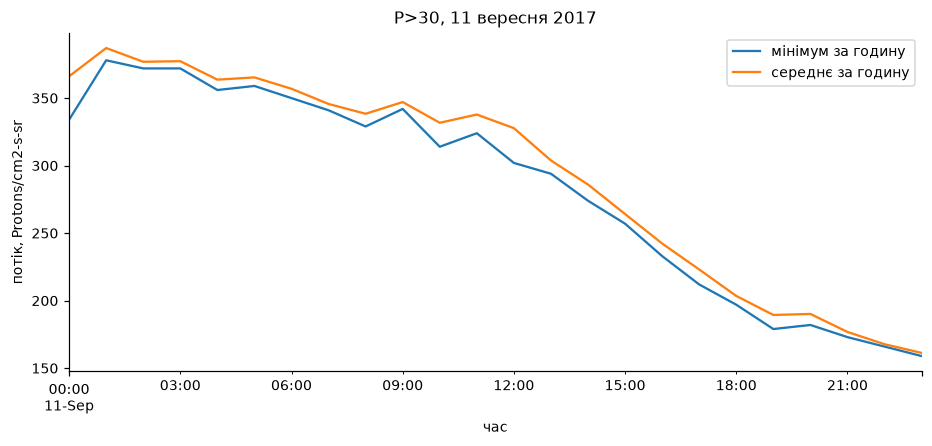

                     мінімум за годину  середнє за годину
ts                                                       
2017-09-11 00:00:00              334.0              366.2
2017-09-11 01:00:00              378.0              387.1
2017-09-11 02:00:00              372.0              376.9
2017-09-11 03:00:00              372.0              377.3
2017-09-11 04:00:00              356.0              363.7
2017-09-11 05:00:00              359.0              365.3
2017-09-11 06:00:00              350.0              356.9
2017-09-11 07:00:00              341.0              345.7
2017-09-11 08:00:00              329.0              338.4
2017-09-11 09:00:00              342.0              347.1
2017-09-11 10:00:00              314.0              331.8
2017-09-11 11:00:00              324.0              337.8
2017-09-11 12:00:00              302.0              327.8
2017-09-11 13:00:00              294.0              303.8
2017-09-11 14:00:00              274.0              286.0
2017-09-11 15:

In [15]:
day = pd.Timestamp('2017-09-11')
day_rows = A[A['ts'].dt.normalize() == day]
one = day_rows.set_index('ts')['P30'].resample('h').agg(['min', 'mean'])
one.columns = ['мінімум за годину', 'середнє за годину']

one.plot(figsize=(10, 4))
plt.title('P>30, 11 вересня 2017')
plt.xlabel('час')
plt.ylabel('потік, Protons/cm2-s-sr')
plt.show()

print(one.round(1).to_string())

**Відповідь 4.2:** *Криві однакові за формою, обидві спадають за добу приблизно з 366 до 161. Мінімум весь час нижче середнього, різниця від 1.8 до 32. Так виходить бо мінімум бере найгірші 5 хвилин з години, а середнє рахує всі 12. Поки потік міняється плавно, різниця мала*

### Завдання 4.3
Об'єднайте три таблиці в одну — назвіть її `M`. Виведіть її розмір і всі рядки,
у яких є хоча б один пропуск.

**Зверніть увагу:** таблиці закінчуються не в один і той самий момент. Тому результат
залежить від того, який тип об'єднання ви оберете (`how='inner'` чи `how='outer'`).
Спробуйте обидва, подивіться, чим відрізняється кількість рядків, і поясніть свій вибір.

In [16]:
for how in ['inner', 'outer']:
    print(how, len(Ah.merge(C[['ts','SPEED','DENSITY']], on='ts', how=how)))

M = Ah.merge(C[['ts','SPEED','DENSITY']], on='ts', how='inner')

M['день'] = M['ts'].dt.normalize()
Bd = B[['ts','F107']].copy()
Bd['день'] = Bd['ts'].dt.normalize()
M = M.merge(Bd[['день','F107']], on='день', how='left')
M = M.drop(columns='день')

print(M.shape)
M[M.isna().any(axis=1)]

inner 600
outer 601
(600, 20)


,ts,P1_mean,P1_max,P5_mean,P5_max,P10_mean,P10_max,P30_mean,P30_max,P50_mean,P50_max,P100_mean,P100_max,E08_mean,E08_max,E20_mean,E20_max,SPEED,DENSITY,F107
175,2017-09-04 07:00:00,6.465833,10.10,0.262083,0.593,0.171500,0.294,0.085483,0.145,0.068558,0.134,0.031717,0.0523,90600.000000,100000.0,7410.833333,8950.0,NaN,NaN,140
176,2017-09-04 08:00:00,4.010833,5.08,0.256000,0.432,0.195833,0.336,0.086625,0.145,0.070033,0.134,0.036492,0.0546,73483.333333,79300.0,5048.333333,5850.0,NaN,NaN,140
177,2017-09-04 09:00:00,3.268333,4.42,0.303417,0.518,0.220333,0.302,0.105925,0.162,0.081975,0.134,0.046483,0.0765,60475.000000,68500.0,3715.833333,4480.0,NaN,NaN,140
178,2017-09-04 10:00:00,3.179167,4.74,0.252167,0.372,0.181833,0.280,0.101900,0.150,0.081675,0.120,0.054125,0.0894,64383.333333,68400.0,4122.500000,4710.0,NaN,NaN,140
179,2017-09-04 11:00:00,5.274167,7.98,0.295083,0.657,0.186917,0.276,0.089525,0.166,0.063983,0.110,0.033633,0.0684,79933.333333,88200.0,6345.833333,7430.0,NaN,NaN,140
180,2017-09-04 12:00:00,2.965000,4.85,0.217750,0.428,0.153500,0.239,0.089217,0.179,0.071217,0.144,0.037233,0.0679,80516.666667,88700.0,6080.000000,7420.0,NaN,NaN,140
181,2017-09-04 13:00:00,3.061667,3.86,0.275833,0.551,0.192833,0.329,0.104542,0.170,0.083783,0.159,0.041342,0.0611,76733.333333,85900.0,6015.833333,7540.0,NaN,NaN,140
182,2017-09-04 14:00:00,7.279167,10.80,0.231333,0.409,0.170583,0.313,0.086508,0.178,0.070667,0.166,0.037375,0.0888,83025.000000,90200.0,8552.500000,10500.0,NaN,NaN,140


**Відповідь 4.3:** *inner дає 600 рядків, outer дає 601. Різниця в одній годині — 22 вересня 00:00, вона є тільки в таблиці C, бо A закінчується 21 вересня о 23:00. В цьому рядку всі 16 стовпців потоку порожні, тому користі з нього немає, він тільки додав би шуму.*

### Завдання 4.4 — поділ на групи
Щоб далі було що з чим порівнювати, поділіть години на три групи за значенням
**максимуму потоку P>10 за годину**:

| Група | Умова |
|---|---|
| `тиха` | менше 10 |
| `активна` | від 10 до 1000 |
| `дуже активна` | 1000 і більше |

Додайте до `M` стовпець `група` і виведіть, скільки годин потрапило в кожну.

> Це не вигадані числа: саме такі пороги використовує метеослужба космічної погоди
> NOAA. Чому вони саме такі — питання не сьогоднішньої роботи.

In [17]:
M['група'] = pd.cut(M['P10_max'],
                    bins=[-1, 10, 1000, float('inf')],
                    labels=['тиха', 'активна', 'дуже активна'],
                    right=False)

M['група'].value_counts().reindex(['тиха', 'активна', 'дуже активна'])

група
тиха            411
активна         171
дуже активна     18
Name: count, dtype: int64

**Самоперевірка етапу 4.**

In [18]:
assert M is not None, 'таблиця M не побудована'
assert 'ts' in M.columns, 'у таблиці M потрібен стовпець ts'
assert 'група' in M.columns, 'у таблиці M потрібен стовпець «група»'
assert 590 <= len(M) <= 605, 'очікується близько 600 рядків, а є %d — перевірте об’єднання' % len(M)
print('Етап 4 пройдено:', len(M), 'рядків')

Етап 4 пройдено: 600 рядків


---
# Етап 5. П'ять графіків — п'ять питань

Графік будується як **відповідь на питання**, а не «щоб був».

**Вимоги до кожного графіка:**

* підписані обидві осі, з одиницями вимірювання;
* заголовок;
* під графіком, у текстовій клітинці, — **одне речення про дані**.
  Не «на графіку зображено потік протонів», а твердження на кшталт
  «більшість годин потік не перевищує 60, але кілька годин дають значення у сотні разів більші».

> Не кожне питання має відповідь «так, зв'язок є». Якщо на графіку нічого не видно —
> так і напишіть. Відсутність зв'язку — це теж результат, і чесно про неї написати
> важливіше, ніж підбирати ракурс, у якому «щось наче проглядається».

### Графік 1. Як розподілені значення вашого потоку?
Побудуйте гістограму вашого потоку (середнє за годину). Порахуйте окремо середнє
й медіану цього стовпця.

Якщо гістограма вийде нечитабельною — стовпчик біля нуля і порожньо далі — не
залишайте так. Спробуйте побудувати гістограму від логарифма значень
(`np.log10`) і подивіться, що зміниться.

**Питання:** чому середнє й медіана так сильно відрізняються?

середнє 18.8313 медіана 0.1378


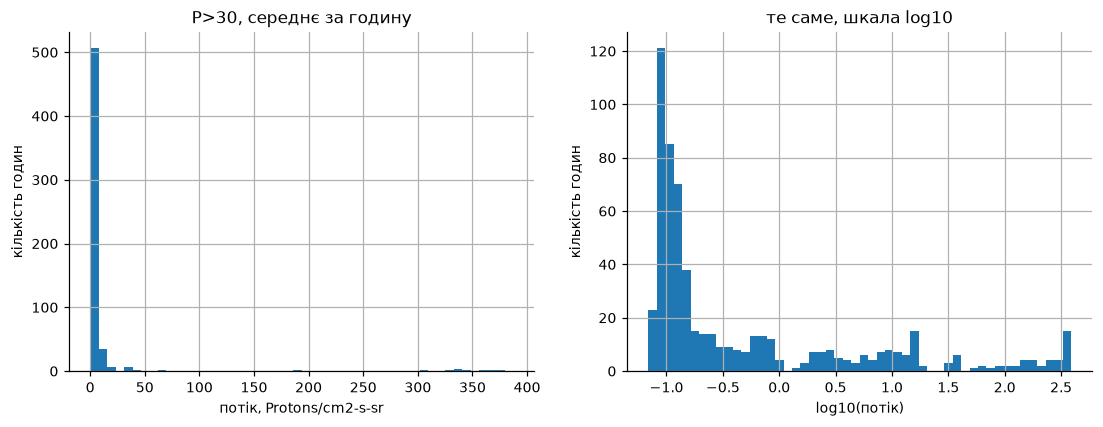

In [19]:
x = M['P30_mean']
print('середнє', round(x.mean(), 4), 'медіана', round(x.median(), 4))

fig, ax = plt.subplots(1, 2, figsize=(12, 4))

x.hist(bins=50, ax=ax[0])
ax[0].set_title('P>30, середнє за годину')
ax[0].set_xlabel('потік, Protons/cm2-s-sr')
ax[0].set_ylabel('кількість годин')

np.log10(x).hist(bins=50, ax=ax[1])
ax[1].set_title('те саме, шкала log10')
ax[1].set_xlabel('log10(потік)')
ax[1].set_ylabel('кількість годин')

plt.show()

**Висновок:** *75.2 відсотка годин мають середній потік P>30 нижче 1, а найбільша година дає 387. Через цей хвіст середнє вийшло 18.83, а медіана 0.138, різниця у 137 разів.*

### Графік 2. Чи відрізняється швидкість вітру між групами годин?
Побудуйте діаграму розмаху (`boxplot`) швидкості сонячного вітру окремо для кожної
групи з завдання 4.4.

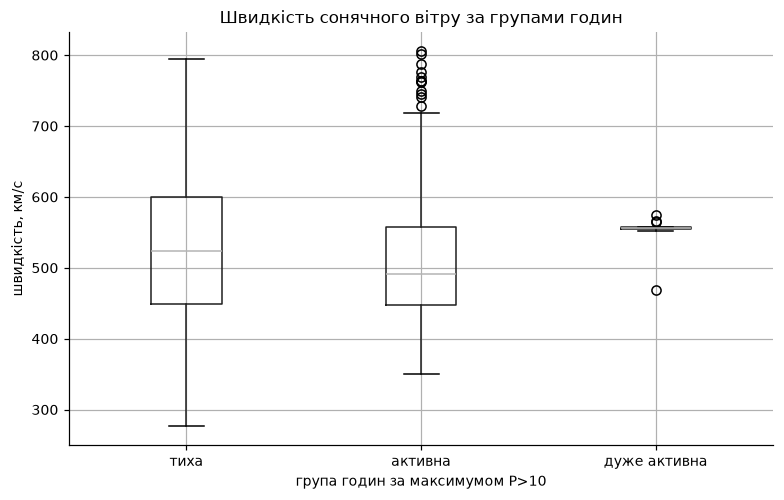

              count  median   mean    min    max
група                                           
тиха            403   524.0  511.3  277.0  795.0
активна         171   492.0  515.1  350.0  806.0
дуже активна     18   556.0  552.9  469.0  575.0


In [20]:
M.boxplot(column='SPEED', by='група', figsize=(8, 5))
plt.title('Швидкість сонячного вітру за групами годин')
plt.suptitle('')
plt.xlabel('група годин за максимумом P>10')
plt.ylabel('швидкість, км/с')
plt.show()

print(M.groupby('група', observed=True)['SPEED'].agg(['count','median','mean','min','max']).round(1))

**Висновок:** *Медіана швидкості вітру в тихих годинах 524, в активних 492, в дуже активних 556. Різниця мала, значить за швидкістю вітру ці групи майже не відрізняються.*

### Графік 3. Чи пов'язані змінні вашої пари?
Побудуйте діаграму розсіювання для пари з вашого завдання. Порахуйте коефіцієнт
кореляції між ними.

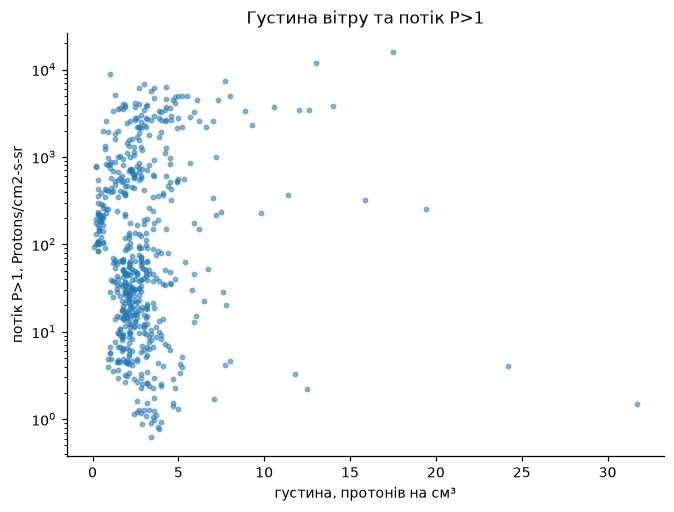

рядків 592 | Pearson 0.285 | Spearman 0.007


In [33]:
p = M[['DENSITY', 'P1_mean']].dropna()

plt.figure(figsize=(7, 5))
plt.scatter(p['DENSITY'], p['P1_mean'], s=8, alpha=0.5)
plt.yscale('log')
plt.title('Густина вітру та потік P>1')
plt.xlabel('густина, протонів на см³')
plt.ylabel('потік P>1, Protons/cm2-s-sr')
plt.show()

print('рядків', len(p),
      '| Pearson', round(p['DENSITY'].corr(p['P1_mean']), 3),
      '| Spearman', round(p['DENSITY'].rank().corr(p['P1_mean'].rank()), 3))

**Висновок:** *Пірсон дає 0.285, а Спірмен 0.007, рахував на 592 годинах. Значить зв'язку між густиною вітру і потоком P>1 немає, а Пірсон показує щось тільки через кілька крайніх точок.*

### Графік 4. Скільки годин у кожній групі?
Побудуйте стовпчикову діаграму кількості годин за групами. Підпишіть кожен стовпчик
кількістю годин і відсотком від загальної кількості.

In [ ]:
vc = M['група'].value_counts().reindex(['тиха', 'активна', 'дуже активна'])

ax = vc.plot.bar(figsize=(7, 5), rot=0)
plt.title('Скільки годин у кожній групі')
plt.xlabel('група')
plt.ylabel('кількість годин')

for i, v in enumerate(vc):
    pct = v / len(M) * 100
    ax.text(i, v + 5, str(v) + '  (' + str(round(pct, 1)) + '%)', ha='center')

plt.show()

**Висновок:** *З 600 годин 411 тихі, це 68.5 відсотка, і тільки 18 дуже активні, це 3 відсотки. Тому середнє по всьому періоду показує спокійний фон, а не шторм.*

### Графік 5. Як усе це виглядало в часі?
Побудуйте лінійний графік максимуму потоку P>10 за годину за весь період спостережень.

Якщо крива виявиться нечитабельною — згадайте, що допомогло в графіку 1.

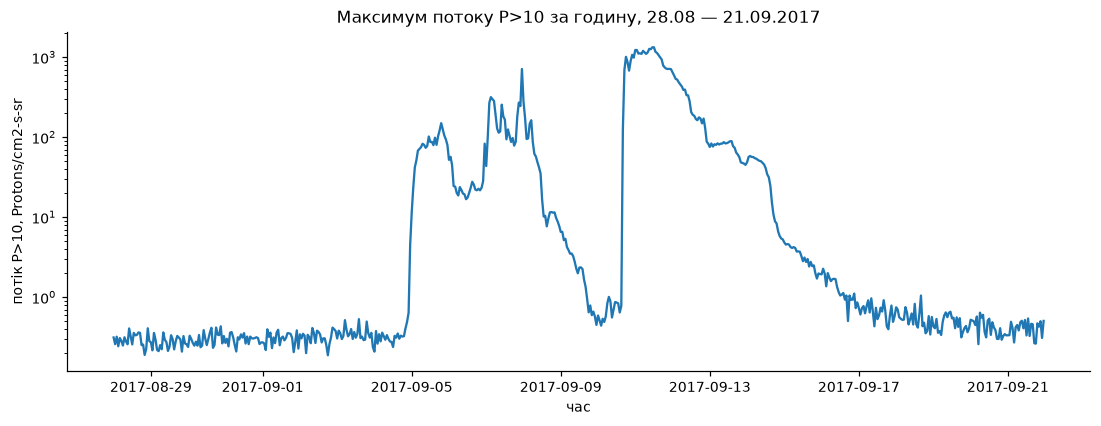

min 0.188 | max 1330.0 | пік 2017-09-11 11:00:00


In [34]:
plt.figure(figsize=(12, 4))
plt.plot(M['ts'], M['P10_max'])
plt.yscale('log')
plt.title('Максимум потоку P>10 за годину, 28.08 — 21.09.2017')
plt.xlabel('час')
plt.ylabel('потік P>10, Protons/cm2-s-sr')
plt.show()

print('min', round(M['P10_max'].min(), 3),
      '| max', M['P10_max'].max(),
      '| пік', M.loc[M['P10_max'].idxmax(), 'ts'])

**Висновок:** Максимум P>10 за годину міняється від 0.19 до 1330, це у 7000 разів. Всі 18 дуже активних годин попали в один епізод 10-11 вересня, і 16 з них ідуть підряд 11 вересня з опівночі до 15:00.

---
# Етап 6. Два графіки одних і тих самих даних

Нижче побудовано два графіки. Дані в них **одні й ті самі** — це той самий стовпець
з тієї самої таблиці, жодне число не змінено.

Виконайте клітинку й подивіться на обидва.

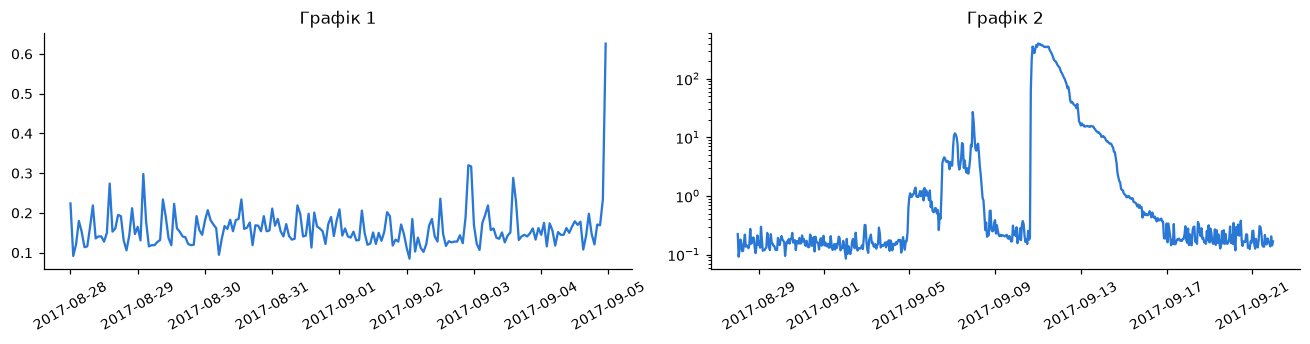

In [21]:
СТОВПЕЦЬ = 'P30_max'

window = M[(M['ts'] >= '2017-08-28') & (M['ts'] < '2017-09-05')]

fig, ax = plt.subplots(1, 2, figsize=(12, 3.2))

ax[0].plot(window['ts'], window[СТОВПЕЦЬ], color='#2a78d6')
ax[0].set_title('Графік 1')
ax[0].tick_params(axis='x', rotation=30)

ax[1].plot(M['ts'], M[СТОВПЕЦЬ], color='#2a78d6')
ax[1].set_yscale('log')
ax[1].set_title('Графік 2')
ax[1].tick_params(axis='x', rotation=30)

fig.tight_layout()
plt.show()

### Завдання 6.1
Дайте відповідь на три питання:

1. Який висновок про космічну погоду у вересні 2017 року зробить людина, яка бачила
   **тільки перший** графік?
2. Який висновок зробить людина, яка бачила **тільки другий**?
3. Чим ці два графіки відрізняються між собою? Назвіть **дві** відмінності —
   вони обидві є в коді вище.

*Жодне число в обох графіках не підроблене. Різниця виникла тільки через те,
як їх побудували.*

**Відповідь 6.1:**

1. Висновок з першого графіка: Людина що побачила його у вересня 2017 скаже що нічого не відбулось, у цей період 192 годин все було тихо.
2. Висновок з другого графіка: ВІдповідно той хто бачив тільки другий скаже про сплеск і що був сильний шторм
3. Дві відмінності між ними: перший показує всі доби і обрізає шторм а інший навпаки


### Завдання 6.2
Уявіть, що вам потрібно **одним графіком** чесно показати, що відбувалося в цьому
періоді. Побудуйте його самі й підпишіть заголовком, який формулює висновок.

Поясніть у клітинці нижче, чому ви обрали саме такий вигляд.

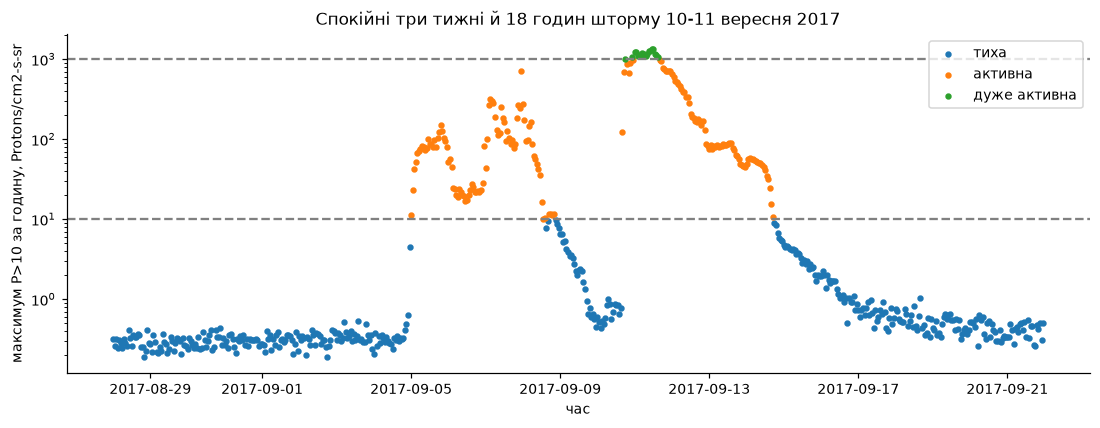

In [22]:
plt.figure(figsize=(12, 4))

for name in ['тиха', 'активна', 'дуже активна']:
    part = M[M['група'] == name]
    plt.scatter(part['ts'], part['P10_max'], s=10, label=name)

plt.yscale('log')
plt.axhline(10, color='gray', linestyle='--')
plt.axhline(1000, color='gray', linestyle='--')
plt.title('Спокійні три тижні й 18 годин шторму 10-11 вересня 2017')
plt.xlabel('час')
plt.ylabel('максимум P>10 за годину, Protons/cm2-s-sr')
plt.legend()
plt.show()

**Відповідь 6.2:** Я взяв весь період що нарізка як на попередніх графіках не зіпсувлаа представлення про шторм, Шкалу поставив логарифмічну, бо розмах 7000 разів і на звичайній осі всі тихі години злипаються в одну лінію. Точки пофарбував за групами і додав лінії на 10 і 1000, щоб було видно звідки взялася класифікація.

---
# Етап 7. Три спостереження та ваше питання

### Завдання 7.1
Запишіть **три спостереження** про ці дані, які ви зробили під час роботи.

Спостереження — це твердження, яке спирається на конкретне число або графік з вашого
ноутбука. Не «дані цікаві», а, наприклад, «максимальне значення потоку у 2000 разів
більше за медіанне, і всі такі години припадають на одні й ті самі три доби».

Для кожного вкажіть, **де саме** у вашій роботі його видно.

**Спостереження 1:** Мітки пропусків у трьох таблицях різні і жодна не є порожньою клітинкою. Таблиця A оголошує -1.00e+05 у шапці й жодного разу його не використовує, а таблиця C не оголошує нічого, але має вісім годин зі значенням -1. Через це isna() показує в C нуль пропусків. Видно в завданні 1.4 і 3.1.

**Спостереження 2:** Весь шторм вміщається у 18 годин з 600, це 3 відсотки часу, і 16 з них ідуть підряд 11 вересня. Максимум погодинного P>10 у 7074 рази більший за мінімум. Видно на графіку 5 і в підрахунку груп у завданні 4.4.

**Спостереження 3:** Пік радіопотоку F10.7 припадає на 4 вересня зі значенням 140, а пік потоку протонів на 11 вересня. Тобто дві міри сонячної активності в цьому вікні розходяться на тиждень. Видно при порівнянні стовпця F107 з графіком 5.




### Завдання 7.2 — ваше індивідуальне питання
Дайте відповідь на додаткове питання зі свого завдання. Відповідь має спиратися
на обчислення: наведіть код і результат, а потім сформулюйте висновок словами.

In [23]:
d = M.set_index('ts')['P30_mean'].resample('D').mean()

print('найбільше', d.idxmax().date(), round(d.max(), 4),
      '| найменше', d.idxmin().date(), round(d.min(), 4),
      '| відношення', round(d.max() / d.min()))

pd.concat([d.nlargest(3), d.nsmallest(3)]).round(4).to_frame('середнє P30 за добу')

найбільше 2017-09-11 292.9306 | найменше 2017-09-01 0.0897 | відношення 3264


,середнє P30 за добу
ts,
2017-09-11,292.9306
2017-09-10,82.2305
2017-09-12,64.7031
2017-09-01,0.0897
2017-09-02,0.0907
2017-08-29,0.0913


**Відповідь 7.2:**  Найбільше середнє за добу потік P>30 мав 11 вересня, 292.93. Найменше 1 вересня, 0.0897. Різниця між ними 3264 рази. Три найактивніші доби йдуть підряд, це 10, 11 і 12 вересня. Найтихіші доби між собою майже не відрізняються, від 0.0897 до 0.0913. Відповідно майже весь потік за три тижні спостережень дали три доби.

---
# Етап 8. Декларація про використання інструментів штучного інтелекту

Користуватися мовними моделями під час виконання цієї роботи **дозволено**. Це
нормальна інженерна практика, і курс про штучний інтелект не має підстав її забороняти.

Обов'язковою є прозорість: ви вказуєте, де саме і як скористалися інструментом —
так само, як у науковій статті вказують використане програмне забезпечення.
**Задекларована допомога порушенням не є.**

Порушенням є інше: здати роботу, яку ви не можете пояснити. На захисті вас попросять
показати конкретний рядок вашого коду, пояснити, чому він саме такий, і внести в нього
невелику зміну на місці. Якщо код згенеровано, але ви його розумієте — робота
зарахована. Якщо не розумієте — не зарахована, незалежно від того, хто його написав.

### Завдання 8.1
Заповніть словник. Для кожного етапу оберіть одне з формулювань:

* `'ні'` — інструментами ШІ не користувався;
* `'синтаксис'` — питав про назву функції або синтаксис, код писав сам;
* `'код, перевірено'` — код згенеровано, я його прочитав, перевірив і розумію;
* `'текст, перероблено'` — згенеровано чернетку тексту, яку я переписав по суті;
* `'текст, як є'` — згенерований текст залишено майже без змін.

Останній варіант не заборонений, але прямо впливає на оцінку: бали ставляться
за висновки, а не за наявність абзацу.

In [35]:
ІНСТРУМЕНТИ_ШІ = 'Claude'

ДЕКЛАРАЦІЯ = {
    'етапи 1–2, читання файлу та розбір таблиць': 'синтаксис',
    'етап 3, паспорт даних і дивні значення':     'код, перевірено',
    'етап 4, об’єднання таблиць':                 'код, перевірено',
    'етап 5, побудова графіків':                  'код, перевірено',
    'етап 5, формулювання висновків':             'текст, перероблено',
    'етапи 6–7, порівняння графіків і спостереження': 'текст, перероблено',
}

ЩО_ПЕРЕВІРЕНО = ('Звірив кількість стовпців: у файлі 32, з них 30 Unnamed і два названі URL-ами. '
    'Спершу порахував 607 заповнених у стовпці AA, перерахував і вийшло 608. '
    'Перевірив межі зрізів: A дає 7200 рядків, B 25, C 601, assert етапу 2 проходить. '
    'Перерахував середнє SPEED до і після заміни -1 на NaN: 506.547 і 513.395. '
    'Перевірив що дуже активних годин 18 і що вони лежать між 18:00 10.09 і 15:00 11.09. '
    'Тексти висновків переписав своїми словами, числа в них звірив зі своїм виводом.')

ПІДТВЕРДЖУЮ = True

In [36]:
ДОЗВОЛЕНІ = {'ні', 'синтаксис', 'код, перевірено', 'текст, перероблено', 'текст, як є'}

assert ІНСТРУМЕНТИ_ШІ.strip(), 'Вкажіть інструменти або напишіть «не використовував»'
порожні = [k for k, v in ДЕКЛАРАЦІЯ.items() if not str(v).strip()]
assert not порожні, 'Не заповнено пункти декларації: %s' % '; '.join(порожні)
чужі = {v for v in ДЕКЛАРАЦІЯ.values() if v not in ДОЗВОЛЕНІ}
assert not чужі, 'Недопустимі значення: %s. Оберіть з переліку вище.' % ', '.join(sorted(чужі))
assert len(ЩО_ПЕРЕВІРЕНО.strip()) >= 120, ('Опишіть конкретніше, що саме ви перевірили '
                                           '(зараз %d символів, потрібно щонайменше 120)'
                                           % len(ЩО_ПЕРЕВІРЕНО.strip()))
assert ПІДТВЕРДЖУЮ is True, 'Підтвердьте, що можете пояснити власний код на захисті'

print('ДЕКЛАРАЦІЯ ПРО ВИКОРИСТАННЯ ІНСТРУМЕНТІВ ШІ · %s · %s' % (ПІБ, ІНСТРУМЕНТИ_ШІ))
print('\n'.join('%-46s %s' % (k + ':', v) for k, v in ДЕКЛАРАЦІЯ.items())
      + '\n' + ЩО_ПЕРЕВІРЕНО)

ДЕКЛАРАЦІЯ ПРО ВИКОРИСТАННЯ ІНСТРУМЕНТІВ ШІ · Савков Олександр · Claude
етапи 1–2, читання файлу та розбір таблиць:    синтаксис
етап 3, паспорт даних і дивні значення:        код, перевірено
етап 4, об’єднання таблиць:                    код, перевірено
етап 5, побудова графіків:                     код, перевірено
етап 5, формулювання висновків:                текст, перероблено
етапи 6–7, порівняння графіків і спостереження: текст, перероблено
Звірив кількість стовпців: у файлі 32, з них 30 Unnamed і два названі URL-ами. Спершу порахував 607 заповнених у стовпці AA, перерахував і вийшло 608. Перевірив межі зрізів: A дає 7200 рядків, B 25, C 601, assert етапу 2 проходить. Перерахував середнє SPEED до і після заміни -1 на NaN: 506.547 і 513.395. Перевірив що дуже активних годин 18 і що вони лежать між 18:00 10.09 і 15:00 11.09. Тексти висновків переписав своїми словами, числа в них звірив зі своїм виводом.


---
# Крок 9. Збереження результату та фінальна самоперевірка

Об'єднана таблиця знадобиться вам у лабораторних роботах № 3 і № 4 — збережіть її
й не втрачайте до кінця семестру.

In [37]:
M.to_csv('master_hourly.csv', index=False)
print('збережено:', M.shape)

збережено: (600, 21)


In [38]:
перевірки = {
    'ПІБ і варіант заповнено':        bool(ПІБ) and bool(ВАРІАНТ),
    'таблиця A (7200 рядків)':        len(A) == 7200,
    'таблиця B (25 рядків)':          len(B) == 25,
    'таблиця C (601 рядок)':          len(C) == 601,
    'таблиці об’єднано':              M is not None and 590 <= len(M) <= 605,
    'стовпець «група» є':             'група' in M.columns,
    'усі дати у 2017 році':           int(pd.to_datetime(M['ts']).dt.year.min()) == 2017,
    'декларацію заповнено':           bool(ІНСТРУМЕНТИ_ШІ.strip()) and ПІДТВЕРДЖУЮ is True,
}
for k, v in перевірки.items():
    print(('OK   ' if v else 'НЕ ОК') + '  ' + k)

if all(перевірки.values()):
    print('\nТехнічна частина роботи виконана. Перевірте, що заповнені всі клітинки '
          'з відповідями та висновками, і виконайте Kernel → Restart & Run All перед здачею.')

OK     ПІБ і варіант заповнено
OK     таблиця A (7200 рядків)
OK     таблиця B (25 рядків)
OK     таблиця C (601 рядок)
OK     таблиці об’єднано
OK     стовпець «група» є
OK     усі дати у 2017 році
OK     декларацію заповнено

Технічна частина роботи виконана. Перевірте, що заповнені всі клітинки з відповідями та висновками, і виконайте Kernel → Restart & Run All перед здачею.
